# Tugas Besar 1 JST (IT6053): Klasifikasi Kualitas Keripik Kentang dengan Perceptron dan ADALINE
**Kelompok XX** — Hansel Ivano Supratman (71231039) & Nicolas Krisna Prawirajati (71231019)

Notebook ini dapat dijalankan dari awal sampai akhir (*Kernel → Restart & Run All*) dengan `dataset.csv` di folder yang sama.
Alur: (1) data & pembagian, (2) implementasi Perceptron, (3) implementasi ADALINE, (4) perhitungan manual terverifikasi kode,
(5) delapan pelatihan, (6) hasil & kurva, (7) decision boundary, (8) analisis keterpisahan linear dan perbandingan model.

**Sumber teknis yang diadaptasi**
- Rosenblatt (1958): aturan koreksi Perceptron berbasis kesalahan tanda prediksi.
- Widrow & Hoff (1960): aturan LMS / Delta Rule untuk ADALINE (galat dihitung dari keluaran linear).
- Raschka, mlxtend *Adaline* (dokumentasi): struktur `fit`/`predict`, `net_input`, dan pembaruan *batch gradient descent*.
  Perubahan kami: bias ikut diperbarui secara eksplisit, loss memakai J = 1/(2n)·Σe² (bukan MSE), loss dicatat **sebelum** pembaruan setiap epoch dan juga **sesudah** epoch terakhir, serta ada penanganan divergensi (loss tak hingga/NaN).

In [1]:
import sys, json, warnings
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg") if False else None
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score

SEED, TEST_SIZE, N_EPOCH = 42, 0.20, 50
ETAS = [0.001, 0.01, 0.1]
ETA_FOCUS = 0.01          # ditetapkan SEBELUM evaluasi data uji (nilai tengah); bukan dipilih dari data uji
FIG = "figures/"
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| matplotlib", matplotlib.__version__, "| scikit-learn", sklearn.__version__)

Python 3.14.3 | numpy 2.4.4 | pandas 3.0.2 | matplotlib 3.10.8 | scikit-learn 1.8.0


## 1. Data dan pembagian latih/uji
- Fitur: `mean_red`, `mean_green` (rata-rata intensitas kanal R dan G citra keripik kentang; numerik).
- Label: **+1 = Good (kelas positif)**, **−1 = Rotten**. Kelas *Defective* pada Tugas 1 tidak dipakai karena tugas ini dua kelas.
- Pembagian 80:20, stratifikasi kelas, `random_state=42`; **pembagian yang sama dipakai untuk kedua model**.
- Rata-rata & simpangan baku standardisasi dipelajari **hanya dari data latih**, lalu diterapkan ke data uji.

In [3]:
df = pd.read_csv("dataset.csv")
df["label"] = df["label"].astype(int)
print("Jumlah observasi :", len(df))
print("Missing value    :", int(df.isna().sum().sum()))
print("Baris duplikat   :", int(df.duplicated().sum()))
print("Distribusi kelas :", df["label"].value_counts().sort_index().to_dict())
display(df.groupby("label")[["mean_red","mean_green"]].agg(["mean","std","min","max"]).round(2))

X = df[["mean_red","mean_green"]].to_numpy(float)
y = df["label"].to_numpy(int)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)
scaler = StandardScaler().fit(X_tr)                 # hanya data latih
Z_tr, Z_te = scaler.transform(X_tr), scaler.transform(X_te)
print("\nLatih:", X_tr.shape, np.bincount(y_tr+1)[[0,2]], "(-1,+1) | Uji:", X_te.shape, np.bincount(y_te+1)[[0,2]])
print("Mean latih :", scaler.mean_.round(4), "| Std latih:", scaler.scale_.round(4))

Jumlah observasi : 300
Missing value    : 0
Baris duplikat   : 0
Distribusi kelas : {-1: 150, 1: 150}


mean_red                        mean_green                      
          mean    std     min     max       mean    std    min     max
label                                                                 
-1       90.53  18.33   47.58  138.54      79.29  21.80  28.37  124.99
 1      141.42  15.98  100.70  189.95     121.22  14.03  89.65  155.04


Latih: (240, 2) [120 120] (-1,+1) | Uji: (60, 2) [30 30]
Mean latih : [115.1479 101.2914] | Std latih: [29.9649 27.8312]


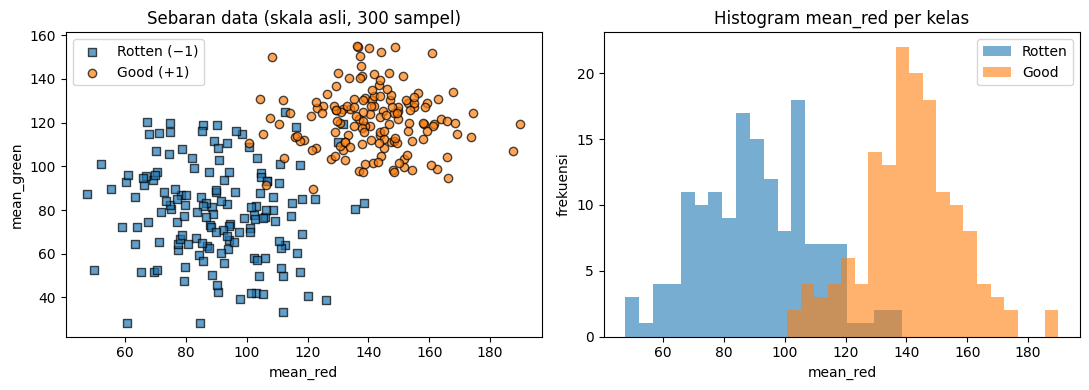

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for c, m, n in [(-1, "s", "Rotten (−1)"), (1, "o", "Good (+1)")]:
    ax[0].scatter(X[y==c,0], X[y==c,1], marker=m, alpha=.7, edgecolor="k", label=n)
ax[0].set(xlabel="mean_red", ylabel="mean_green", title="Sebaran data (skala asli, 300 sampel)"); ax[0].legend()
for c, n in [(-1,"Rotten"), (1,"Good")]:
    ax[1].hist(X[y==c,0], bins=20, alpha=.6, label=n)
ax[1].set(xlabel="mean_red", ylabel="frekuensi", title="Histogram mean_red per kelas"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG+"fig_data.png", dpi=150); plt.show()

## 2. Implementasi Perceptron (NumPy)
Neuron: z = wᵀx + b; ŷ = +1 jika z ≥ 0, selainnya −1. Untuk tiap sampel (urutan tetap, tanpa *shuffle*): Δ = η(y − ŷ); w ← w + Δ·x; b ← b + Δ. Inisialisasi w = 0, b = 0.

In [5]:
class PerceptronScratch:
    def __init__(self, eta=0.01, n_epoch=50):
        self.eta, self.n_epoch = eta, n_epoch
    def net_input(self, X):
        return np.asarray(X) @ self.w_ + self.b_
    def predict(self, X):
        return np.where(self.net_input(X) >= 0.0, 1, -1)
    def fit(self, X, y):
        self.w_, self.b_ = np.zeros(X.shape[1]), 0.0
        self.mistakes_, self.train_err_, self.w_hist_, self.b_hist_ = [], [], [], []
        for _ in range(self.n_epoch):
            n_upd = 0
            for xi, target in zip(X, y):
                delta = self.eta * (target - self.predict(xi))   # 0 jika benar, ±2η jika salah
                self.w_ = self.w_ + delta * xi
                self.b_ = self.b_ + delta
                n_upd += int(delta != 0.0)
            self.mistakes_.append(n_upd)                          # jumlah pembaruan salah-klasifikasi epoch ini
            self.train_err_.append(int((self.predict(X) != y).sum())) # kesalahan latih SETELAH epoch ini
            self.w_hist_.append(self.w_.copy()); self.b_hist_.append(self.b_)
        return self

## 3. Implementasi ADALINE + Delta Rule (batch gradient descent)
Galeat memakai **keluaran linear** z: e = y − z. Pembaruan: w ← w + η·Xᵀe/n; b ← b + η·mean(e). Fungsi objektif J = (1/2n)Σe² (MSE = 2J). Loss per epoch dicatat **sebelum** pembaruan epoch tersebut; `J_after_` dihitung dari parameter akhir (sesudah pembaruan ke-50). Ambang ŷ hanya dipakai saat prediksi. Jika loss tak hingga/NaN, pelatihan dihentikan dan epoch kejadian dicatat.

In [6]:
class AdalineGDScratch:
    def __init__(self, eta=0.01, n_epoch=50):
        self.eta, self.n_epoch = eta, n_epoch
    def net_input(self, X):
        with np.errstate(all="ignore"):
            return np.asarray(X) @ self.w_ + self.b_
    def predict(self, X):
        return np.where(self.net_input(X) >= 0.0, 1, -1)
    def J(self, X, y):
        with np.errstate(all="ignore"):
            return float(0.5 * np.mean((y - self.net_input(X)) ** 2))
    def fit(self, X, y):
        self.w_, self.b_ = np.zeros(X.shape[1]), 0.0
        self.losses_, self.w_hist_, self.b_hist_ = [], [], []
        self.diverged_epoch_ = None   # epoch saat loss tak hingga / NaN
        self.blowup_epoch_ = None     # epoch pertama saat J > 1e6 (meledak walau belum tak hingga)
        n = X.shape[0]
        for ep in range(1, self.n_epoch + 1):
            with np.errstate(all="ignore"):
                e = y - self.net_input(X)                 # galat dari keluaran LINEAR
                loss = float(0.5 * np.mean(e ** 2))        # J sebelum pembaruan epoch ini
            if not np.isfinite(loss):
                self.diverged_epoch_ = ep; break           # hentikan, catat epoch kejadian
            self.losses_.append(loss)
            if self.blowup_epoch_ is None and loss > 1e6: self.blowup_epoch_ = ep
            self.w_ = self.w_ + self.eta * (X.T @ e) / n
            self.b_ = self.b_ + self.eta * e.mean()
            self.w_hist_.append(self.w_.copy()); self.b_hist_.append(self.b_)
        self.J_after_ = self.J(X, y)
        return self

## 4. Perhitungan manual (terverifikasi kode)
Memakai **dua sampel latih pertama** (terstandardisasi), η = 0,01, w = [0,0], b = 0.
Perceptron: dua sampel diproses berurutan. ADALINE: batch n = 2, dua iterasi.

In [7]:
xs, ys, eta = Z_tr[:2], y_tr[:2], 0.01
np.set_printoptions(precision=6, suppress=True)
print("x1 =", xs[0], " y1 =", ys[0]); print("x2 =", xs[1], " y2 =", ys[1]); print()

# ---- Perceptron manual
w, b = np.zeros(2), 0.0
print("=== PERCEPTRON ===")
for i,(x_i,t) in enumerate(zip(xs, ys), 1):
    z = w @ x_i + b; yh = 1 if z >= 0 else -1; d = eta * (t - yh)
    print(f"Sampel {i}: z = {z:.4f} -> y_hat = {yh:+d}; delta = {eta}*({t}-({yh})) = {d:+.4f}")
    w = w + d * x_i; b = b + d
    print(f"          w = {w}, b = {b:+.4f}")
w_p_manual, b_p_manual = w.copy(), b

# ---- ADALINE manual (batch n=2, 2 iterasi)
w, b = np.zeros(2), 0.0
print("\n=== ADALINE (batch n=2) ===")
for it in (1, 2):
    z = xs @ w + b; e = ys - z; J = 0.5*np.mean(e**2)
    grad_w = xs.T @ e / len(xs); grad_b = e.mean()
    print(f"Iterasi {it}: z = {z}, e = {e}, J(sebelum) = {J:.6f}")
    print(f"           X^T e / n = {grad_w}, mean(e) = {grad_b:.6f}")
    w = w + eta * grad_w; b = b + eta * grad_b
    print(f"           w = {w}, b = {b:+.6f}")
w_a_manual, b_a_manual = w.copy(), b

# ---- verifikasi terhadap kelas
p = PerceptronScratch(eta, 1).fit(xs, ys)
a = AdalineGDScratch(eta, 2).fit(xs, ys)
assert np.allclose(p.w_, w_p_manual) and np.isclose(p.b_, b_p_manual)
assert np.allclose(a.w_, w_a_manual) and np.isclose(a.b_, b_a_manual)
print("\nVERIFIKASI: perhitungan manual == keluaran kelas (Perceptron & ADALINE) -> OK")

x1 = [0.515514 0.285579]  y1 = 1
x2 = [-1.417542 -0.464243]  y2 = -1

=== PERCEPTRON ===
Sampel 1: z = 0.0000 -> y_hat = +1; delta = 0.01*(1-(1)) = +0.0000
          w = [0. 0.], b = +0.0000
Sampel 2: z = 0.0000 -> y_hat = +1; delta = 0.01*(-1-(1)) = -0.0200
          w = [0.028351 0.009285], b = -0.0200

=== ADALINE (batch n=2) ===
Iterasi 1: z = [0. 0.], e = [ 1. -1.], J(sebelum) = 0.500000
           X^T e / n = [0.966528 0.374911], mean(e) = 0.000000
           w = [0.009665 0.003749], b = +0.000000
Iterasi 2: z = [ 0.006053 -0.015441], e = [ 0.993947 -0.984559], J(sebelum) = 0.489321
           X^T e / n = [0.954023 0.370462], mean(e) = 0.004694
           w = [0.019206 0.007454], b = +0.000047

VERIFIKASI: perhitungan manual == keluaran kelas (Perceptron & ADALINE) -> OK


## 5. Delapan pelatihan
Enam konfigurasi terstandardisasi (η ∈ {0,001; 0,01; 0,1}, 50 epoch, tiap model) + dua tanpa standardisasi (η = 0,01, 50 epoch).
Pembagian data, inisialisasi (w = 0, b = 0), dan urutan sampel sama untuk semua. Data uji hanya dipakai untuk pelaporan konfigurasi yang sudah ditetapkan.

In [8]:
def run(model_name, eta, std):
    A_tr, A_te = (Z_tr, Z_te) if std else (X_tr, X_te)
    m = (PerceptronScratch if model_name == "Perceptron" else AdalineGDScratch)(eta, N_EPOCH).fit(A_tr, y_tr)
    ptr, pte = m.predict(A_tr), m.predict(A_te)
    cm = confusion_matrix(y_te, pte, labels=[-1, 1])
    r = dict(Model=model_name, eta=eta, Epoch=N_EPOCH, Standardisasi="Ya" if std else "Tidak",
             Acc_latih=accuracy_score(y_tr, ptr), Acc_uji=accuracy_score(y_te, pte),
             Salah_latih_akhir=int((ptr != y_tr).sum()),
             TN=int(cm[0,0]), FP=int(cm[0,1]), FN=int(cm[1,0]), TP=int(cm[1,1]),
             Precision=precision_score(y_te, pte, pos_label=1, zero_division=0),
             Recall=recall_score(y_te, pte, pos_label=1, zero_division=0),
             F1=f1_score(y_te, pte, pos_label=1, zero_division=0),
             w1=m.w_[0], w2=m.w_[1], b=m.b_)
    if model_name == "Perceptron":
        h = m.mistakes_
        r.update(Update_ep10=h[9], Update_ep30=h[29], Update_ep50=h[49], Loss_akhir=None,
                 J_ep10=None, J_ep30=None, J_ep50=None, Divergen_epoch=None, Meledak_epoch=None)
    else:
        L = m.losses_
        g = lambda k: L[k-1] if len(L) >= k else None
        r.update(Update_ep10=None, Update_ep30=None, Update_ep50=None, Loss_akhir=m.J_after_,
                 J_ep10=g(10), J_ep30=g(30), J_ep50=g(50), Divergen_epoch=m.diverged_epoch_, Meledak_epoch=m.blowup_epoch_)
    return r, m

CONFIGS = [(mn, e, True) for mn in ("Perceptron","ADALINE") for e in ETAS] + [(mn, 0.01, False) for mn in ("Perceptron","ADALINE")]
rows, models = [], {}
for cfg in CONFIGS:
    r, m = run(*cfg); rows.append(r); models[cfg] = m
res = pd.DataFrame(rows)
print("Jumlah pelatihan:", len(res))

Jumlah pelatihan: 8


### 5.1 Tabel seluruh konfigurasi

In [9]:
t = res[["Model","eta","Epoch","Standardisasi","Acc_latih","Acc_uji","Salah_latih_akhir","Loss_akhir","w1","w2","b","Divergen_epoch","Meledak_epoch"]].copy()
t["Acc_latih"] = (t["Acc_latih"]*100).round(2); t["Acc_uji"] = (t["Acc_uji"]*100).round(2)
t["Loss_akhir (J)"] = t["Loss_akhir"].map(lambda v: "-" if pd.isna(v) else ("inf" if not np.isfinite(v) else f"{v:.4g}"))
t = t.drop(columns="Loss_akhir")
for c in ("w1","w2","b"): t[c] = t[c].map(lambda v: f"{v:.4g}")
display(t)
print("Catatan: J ADALINE = 1/(2n)·Σe² dihitung dari parameter akhir (sesudah epoch ke-50). 'Salah_latih_akhir' = jumlah sampel latih salah klasifikasi setelah epoch terakhir (dari 240).")

,Model,eta,Epoch,Standardisasi,Acc_latih,Acc_uji,Salah_latih_akhir,w1,w2,b,Divergen_epoch,Meledak_epoch,Loss_akhir (J)
0,Perceptron,0.001,50,Ya,96.25,96.67,9,0.002017,0.001354,0,None,NaN,-
1,Perceptron,0.010,50,Ya,96.25,96.67,9,0.02017,0.01354,0,None,NaN,-
2,Perceptron,0.100,50,Ya,96.25,96.67,9,0.2017,0.1354,0,None,NaN,-
3,ADALINE,0.001,50,Ya,96.67,96.67,8,0.04026,0.03677,1.373e-18,None,NaN,0.4406
4,ADALINE,0.010,50,Ya,96.25,96.67,9,0.2917,0.2594,9.492e-17,None,NaN,0.181
5,ADALINE,0.100,50,Ya,96.25,96.67,9,0.5727,0.4112,6.902e-16,None,NaN,0.1024
6,Perceptron,0.010,50,Tidak,44.17,45.00,134,1.085,-1.479,-26.54,None,NaN,-
7,ADALINE,0.010,50,Tidak,50.00,50.00,120,-5.078e+116,-4.469e+116,-4.169e+114,None,3.0,5.693e+237


Catatan: J ADALINE = 1/(2n)·Σe² dihitung dari parameter akhir (sesudah epoch ke-50). 'Salah_latih_akhir' = jumlah sampel latih salah klasifikasi setelah epoch terakhir (dari 240).


In [10]:
h = res[["Model","eta","Standardisasi","Update_ep10","Update_ep30","Update_ep50","J_ep10","J_ep30","J_ep50"]].copy()
for c in ("J_ep10","J_ep30","J_ep50"): h[c] = h[c].map(lambda v: "-" if pd.isna(v) else f"{v:.4g}")
print("Riwayat pelatihan pada epoch ke-10/30/50 (Perceptron: jumlah pembaruan salah; ADALINE: J sebelum pembaruan epoch tsb)")
display(h)
ra = models[("ADALINE",0.01,False)]
print("ADALINE η=0,01 tanpa standardisasi — J lima epoch pertama:", [f"{v:.4g}" for v in ra.losses_[:5]])
print("J pertama > 1e6 pada epoch:", ra.blowup_epoch_, "| loss tak hingga/NaN dalam 50 epoch:", ra.diverged_epoch_ if ra.diverged_epoch_ else "tidak terjadi (J hingga tetapi ~1e232)")
print("Bila dilatih lebih dari 50 epoch, loss akan menjadi tak hingga (overflow float64); pelatihan akan dihentikan dan epochnya dicatat oleh kelas.")
_long = AdalineGDScratch(0.01, 200).fit(X_tr, y_tr)
print("Diagnostik 200 epoch: loss tak hingga/NaN pertama pada epoch", _long.diverged_epoch_)

Riwayat pelatihan pada epoch ke-10/30/50 (Perceptron: jumlah pembaruan salah; ADALINE: J sebelum pembaruan epoch tsb)


,Model,eta,Standardisasi,Update_ep10,Update_ep30,Update_ep50,J_ep10,J_ep30,J_ep50
0,Perceptron,0.001,Ya,10.0,12.0,10.0,-,-,-
1,Perceptron,0.010,Ya,10.0,12.0,10.0,-,-,-
2,Perceptron,0.100,Ya,10.0,12.0,10.0,-,-,-
3,ADALINE,0.001,Ya,NaN,NaN,NaN,0.4886,0.4644,0.4417
4,ADALINE,0.010,Ya,NaN,NaN,NaN,0.3989,0.2572,0.1835
5,ADALINE,0.100,Ya,NaN,NaN,NaN,0.1201,0.1027,0.1024
6,Perceptron,0.010,Tidak,129.0,117.0,121.0,-,-,-
7,ADALINE,0.010,Tidak,NaN,NaN,NaN,2.709e+41,1.585e+137,9.268e+232


ADALINE η=0,01 tanpa standardisasi — J lima epoch pertama: ['0.5', '1337', '8.21e+07', '5.043e+12', '3.098e+17']
J pertama > 1e6 pada epoch: 3 | loss tak hingga/NaN dalam 50 epoch: tidak terjadi (J hingga tetapi ~1e232)
Bila dilatih lebih dari 50 epoch, loss akan menjadi tak hingga (overflow float64); pelatihan akan dihentikan dan epochnya dicatat oleh kelas.
Diagnostik 200 epoch: loss tak hingga/NaN pertama pada epoch 66


### 5.2 Confusion matrix data uji (urutan label: [−1 Rotten, +1 Good]; baris = aktual, kolom = prediksi)

In [11]:
cm_tab = res[["Model","eta","Standardisasi","TN","FP","FN","TP","Precision","Recall","F1"]].copy()
for c in ("Precision","Recall","F1"): cm_tab[c] = cm_tab[c].round(4)
display(cm_tab)
for cfg in CONFIGS:
    m = models[cfg]; A_te = Z_te if cfg[2] else X_te
    print(cfg[0], "eta=", cfg[1], "std" if cfg[2] else "raw", "\n", confusion_matrix(y_te, m.predict(A_te), labels=[-1,1]))

,Model,eta,Standardisasi,TN,FP,FN,TP,Precision,Recall,F1
0,Perceptron,0.001,Ya,29,1,1,29,0.9667,0.9667,0.9667
1,Perceptron,0.010,Ya,29,1,1,29,0.9667,0.9667,0.9667
2,Perceptron,0.100,Ya,29,1,1,29,0.9667,0.9667,0.9667
3,ADALINE,0.001,Ya,29,1,1,29,0.9667,0.9667,0.9667
4,ADALINE,0.010,Ya,29,1,1,29,0.9667,0.9667,0.9667
5,ADALINE,0.100,Ya,29,1,1,29,0.9667,0.9667,0.9667
6,Perceptron,0.010,Tidak,24,6,27,3,0.3333,0.1000,0.1538
7,ADALINE,0.010,Tidak,30,0,30,0,0.0000,0.0000,0.0000


Perceptron eta= 0.001 std 
 [[29  1]
 [ 1 29]]
Perceptron eta= 0.01 std 
 [[29  1]
 [ 1 29]]
Perceptron eta= 0.1 std 
 [[29  1]
 [ 1 29]]
ADALINE eta= 0.001 std 
 [[29  1]
 [ 1 29]]
ADALINE eta= 0.01 std 
 [[29  1]
 [ 1 29]]
ADALINE eta= 0.1 std 
 [[29  1]
 [ 1 29]]
Perceptron eta= 0.01 raw 
 [[24  6]
 [27  3]]
ADALINE eta= 0.01 raw 
 [[30  0]
 [30  0]]


### 5.3 Perhitungan confusion matrix secara manual (NumPy) dan verifikasi
Matriks 2×2 dihitung langsung dari definisi, **tanpa** `sklearn`: kelas positif = Good (+1), urutan label `[−1 Rotten, +1 Good]`, baris = aktual, kolom = prediksi.

| | Prediksi −1 (Rotten) | Prediksi +1 (Good) |
|---|---|---|
| **Aktual −1 (Rotten)** | TN | FP |
| **Aktual +1 (Good)** | FN | TP |

Akurasi = (TN+TP)/N · Precision = TP/(TP+FP) · Recall = TP/(TP+FN) · F1 = 2·P·R/(P+R). Bila penyebut 0 (mis. tidak ada prediksi Good), nilainya ditetapkan 0 (sama dengan `zero_division=0` pada kode di atas).
Hasil manual dibandingkan dengan `sklearn` dan tabel 5.2 memakai `assert`.

In [ ]:
def confusion_manual(y_true, y_pred):
    """Matriks kebingungan 2x2 murni NumPy: [[TN, FP], [FN, TP]]; label [-1 Rotten, +1 Good]."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    TN = int(np.sum((y_true == -1) & (y_pred == -1)))
    FP = int(np.sum((y_true == -1) & (y_pred ==  1)))
    FN = int(np.sum((y_true ==  1) & (y_pred == -1)))
    TP = int(np.sum((y_true ==  1) & (y_pred ==  1)))
    return np.array([[TN, FP], [FN, TP]])

def metrik_manual(cm):
    (TN, FP), (FN, TP) = cm
    acc  = (TN + TP) / cm.sum()
    prec = TP / (TP + FP) if (TP + FP) > 0 else 0.0
    rec  = TP / (TP + FN) if (TP + FN) > 0 else 0.0
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    return dict(Akurasi=acc, Precision=prec, Recall=rec, F1=f1)

cms, rows_cm = {}, []
for cfg, (_, r) in zip(CONFIGS, res.iterrows()):
    m = models[cfg]; A_te = Z_te if cfg[2] else X_te
    pred = m.predict(A_te)
    cm = confusion_manual(y_te, pred); mt = metrik_manual(cm); cms[cfg] = cm
    # verifikasi terhadap sklearn dan tabel 5.2
    assert (cm == confusion_matrix(y_te, pred, labels=[-1, 1])).all()
    assert (cm.ravel() == r[["TN", "FP", "FN", "TP"]].to_numpy(int)).all()
    assert all(np.isclose(mt[k], r[c]) for k, c in [("Akurasi","Acc_uji"),("Precision","Precision"),("Recall","Recall"),("F1","F1")])
    rows_cm.append(dict(Model=cfg[0], eta=cfg[1], Standardisasi="Ya" if cfg[2] else "Tidak",
                        TN=cm[0,0], FP=cm[0,1], FN=cm[1,0], TP=cm[1,1], **{k: round(v, 4) for k, v in mt.items()}))
display(pd.DataFrame(rows_cm))
print("VERIFIKASI: confusion matrix & metrik manual == sklearn untuk semua 8 konfigurasi -> OK\n")

# Contoh perhitungan langkah demi langkah (tiga kelompok hasil yang berbeda)
for nama, cfg in [("Terstandardisasi (identik untuk keenam konfigurasi)", ("Perceptron", 0.01, True)),
                  ("Perceptron tanpa standardisasi", ("Perceptron", 0.01, False)),
                  ("ADALINE tanpa standardisasi", ("ADALINE", 0.01, False))]:
    (TN, FP), (FN, TP) = cms[cfg]; N = int(cms[cfg].sum()); mt = metrik_manual(cms[cfg])
    print(f"{nama}: TN={TN} FP={FP} FN={FN} TP={TP} (N={N})")
    print(f"  Akurasi   = ({TN}+{TP})/{N} = {mt['Akurasi']:.4f}")
    print(f"  Precision = {TP}/({TP}+{FP}) = {mt['Precision']:.4f}" + ("  (0/0 -> 0)" if TP + FP == 0 else ""))
    print(f"  Recall    = {TP}/({TP}+{FN}) = {mt['Recall']:.4f}")
    print(f"  F1        = 2*P*R/(P+R) = {mt['F1']:.4f}\n")

# Visualisasi: heatmap confusion matrix data uji
fig, axs = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, cfg in zip(axs, [("Perceptron",0.01,True), ("ADALINE",0.01,True), ("Perceptron",0.01,False), ("ADALINE",0.01,False)]):
    cm = cms[cfg]; ax.imshow(cm, cmap="Blues", vmin=0, vmax=30)
    for i, j in np.ndindex(2, 2):
        ax.text(j, i, f"{cm[i,j]}\n{[['TN','FP'],['FN','TP']][i][j]}", ha="center", va="center",
                fontsize=13, color="white" if cm[i,j] > 15 else "black")
    ax.set(xticks=[0,1], yticks=[0,1], xticklabels=["−1 Rotten","+1 Good"], yticklabels=["−1 Rotten","+1 Good"],
           xlabel="Prediksi", ylabel="Aktual", title=f"{cfg[0]} η={cfg[1]} ({'std' if cfg[2] else 'tanpa std'})")
plt.tight_layout(); plt.savefig(FIG+"fig_confusion.png", dpi=150); plt.show()

## 6. Kurva pelatihan

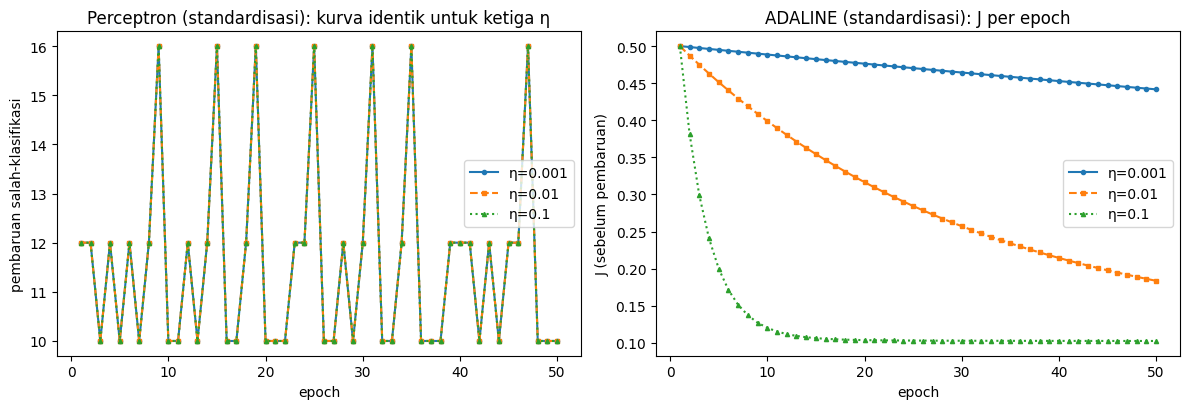

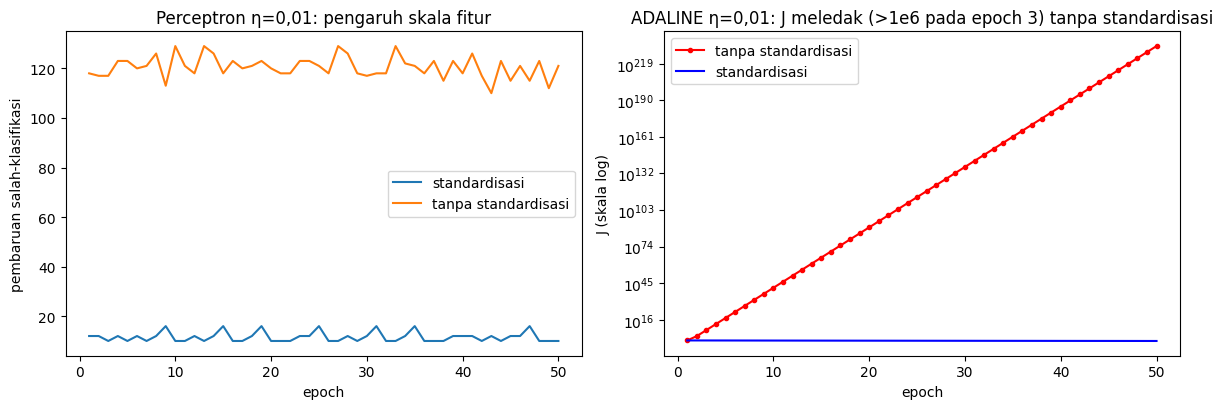

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
sty = {0.001:("-","o"), 0.01:("--","s"), 0.1:(":","^")}
for e in ETAS:
    m = models[("Perceptron", e, True)]
    ax[0].plot(range(1,51), m.mistakes_, ls=sty[e][0], marker=sty[e][1], ms=3, label=f"η={e}")
ax[0].set(xlabel="epoch", ylabel="pembaruan salah-klasifikasi", title="Perceptron (standardisasi): kurva identik untuk ketiga η"); ax[0].legend()
for e in ETAS:
    m = models[("ADALINE", e, True)]
    ax[1].plot(range(1,51), m.losses_, ls=sty[e][0], marker=sty[e][1], ms=3, label=f"η={e}")
ax[1].set(xlabel="epoch", ylabel="J (sebelum pembaruan)", title="ADALINE (standardisasi): J per epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG+"fig_kurva_standar.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
mp_s, mp_r = models[("Perceptron",0.01,True)], models[("Perceptron",0.01,False)]
ax[0].plot(range(1,51), mp_s.mistakes_, label="standardisasi"); ax[0].plot(range(1,51), mp_r.mistakes_, label="tanpa standardisasi")
ax[0].set(xlabel="epoch", ylabel="pembaruan salah-klasifikasi", title="Perceptron η=0,01: pengaruh skala fitur"); ax[0].legend()
ma_r = models[("ADALINE",0.01,False)]
ax[1].semilogy(range(1,len(ma_r.losses_)+1), ma_r.losses_, "r-o", ms=3, label="tanpa standardisasi")
ax[1].semilogy(range(1,51), models[("ADALINE",0.01,True)].losses_, "b-", label="standardisasi")
ax[1].set(xlabel="epoch", ylabel="J (skala log)", title=f"ADALINE η=0,01: J meledak (>1e6 pada epoch {ma_r.blowup_epoch_}) tanpa standardisasi"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG+"fig_kurva_tanpa_standar.png", dpi=150); plt.show()

## 7. Decision boundary (η = 0,01; ditetapkan sebelum evaluasi)
Dua fitur → batas keputusan w₁x₁ + w₂x₂ + b = 0 digambar langsung pada ruang fitur.

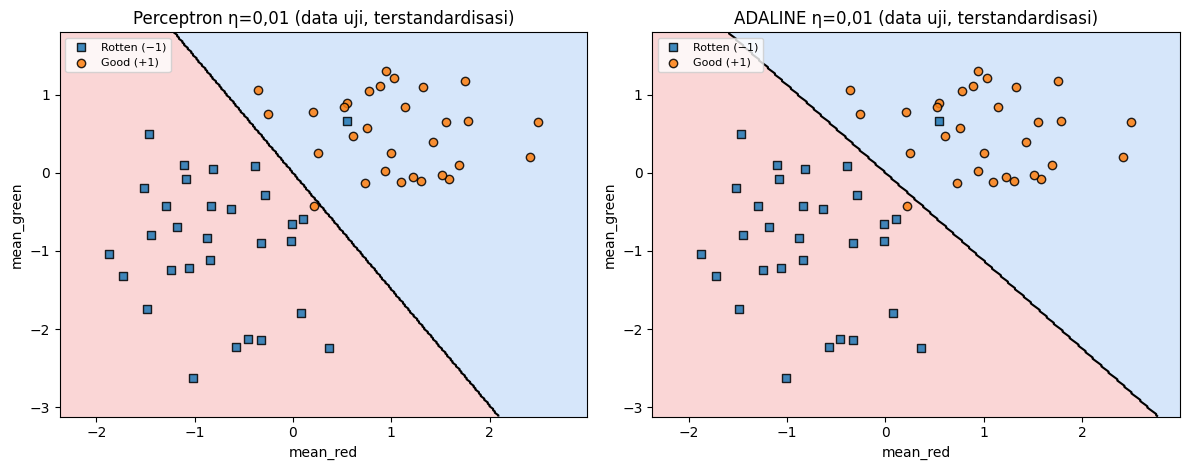

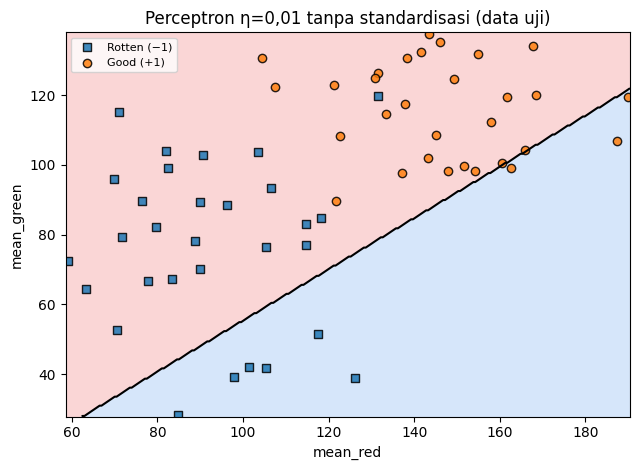

In [13]:
def boundary(ax, m, A, yy, title):
    lo, hi = A.min(0) - .5, A.max(0) + .5
    g1, g2 = np.meshgrid(np.linspace(lo[0], hi[0], 300), np.linspace(lo[1], hi[1], 300))
    zz = m.predict(np.c_[g1.ravel(), g2.ravel()]).reshape(g1.shape)
    ax.contourf(g1, g2, zz, levels=[-2,0,2], colors=["#f4a6a6","#a6c8f4"], alpha=.45)
    ax.contour(g1, g2, zz, levels=[0], colors="k", linewidths=1.5)
    for c, mk, n in [(-1,"s","Rotten (−1)"), (1,"o","Good (+1)")]:
        ax.scatter(A[yy==c,0], A[yy==c,1], marker=mk, edgecolor="k", alpha=.85, label=n)
    ax.set(title=title, xlabel="mean_red", ylabel="mean_green"); ax.legend(loc="upper left", fontsize=8)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
boundary(ax[0], models[("Perceptron",0.01,True)], Z_te, y_te, "Perceptron η=0,01 (data uji, terstandardisasi)")
boundary(ax[1], models[("ADALINE",0.01,True)], Z_te, y_te, "ADALINE η=0,01 (data uji, terstandardisasi)")
plt.tight_layout(); plt.savefig(FIG+"fig_boundary.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 4.8))
boundary(ax, models[("Perceptron",0.01,False)], X_te, y_te, "Perceptron η=0,01 tanpa standardisasi (data uji)")
plt.tight_layout(); plt.savefig(FIG+"fig_boundary_raw.png", dpi=150); plt.show()

## 8. Analisis keterpisahan linear, perbandingan model, dan pemilihan lewat validasi

In [14]:
# (a) Diagnostik keterpisahan linear (HANYA data latih; di luar 8 konfigurasi utama): Perceptron 2000 epoch
diag = PerceptronScratch(0.01, 2000).fit(Z_tr, y_tr)
print("Perceptron 2000 epoch (latih): kesalahan latih minimum =", min(diag.train_err_),
      "| epoch pertama saat minimum:", int(np.argmin(diag.train_err_))+1,
      "| epoch dengan 0 kesalahan latih:", int(sum(e == 0 for e in diag.train_err_)))
print("Pembaruan salah pada epoch 2000:", diag.mistakes_[-1], "(>0 → tidak pernah konvergen penuh)")

# (b) Solusi kuadrat-terkecil tertutup sebagai acuan optimum J untuk ADALINE (latih, terstandardisasi)
Aug = np.c_[Z_tr, np.ones(len(Z_tr))]
theta, *_ = np.linalg.lstsq(Aug, y_tr, rcond=None)
J_opt = 0.5*np.mean((y_tr - Aug@theta)**2)
print(f"\nOptimum kuadrat-terkecil: w={theta[:2].round(4)}, b={theta[2]:.4f}, J_min={J_opt:.4f}")
for e in ETAS:
    print(f"  ADALINE η={e}: J setelah epoch 50 = {models[('ADALINE',e,True)].J_after_:.4f}")
big = AdalineGDScratch(0.1, 5000).fit(Z_tr, y_tr)
print(f"  ADALINE η=0.1, 5000 epoch (diagnostik): w={big.w_.round(4)}, b={big.b_:.4f}, J={big.J_after_:.4f}")

# (c) η pada Perceptron hanya menskalakan bobot
wp = {e: np.r_[models[('Perceptron',e,True)].w_, models[('Perceptron',e,True)].b_] for e in ETAS}
print("\n[w1,w2,b]/η Perceptron:", {e: (wp[e]/e).round(4).tolist() for e in ETAS})

# (d) Akurasi sama ≠ proses sama
mp, ma = models[("Perceptron",0.01,True)], models[("ADALINE",0.01,True)]
agree = float((mp.predict(Z_te) == ma.predict(Z_te)).mean())
ang = lambda m: np.degrees(np.arctan2(m.w_[1], m.w_[0]))
print(f"\nKesepakatan prediksi uji Perceptron vs ADALINE (η=0.01): {agree*100:.1f}%")
print(f"Arah normal batas (derajat): Perceptron {ang(mp):.2f}, ADALINE {ang(ma):.2f} | w2/w1: {mp.w_[1]/mp.w_[0]:.3f} vs {ma.w_[1]/ma.w_[0]:.3f}")
print("Sampel latih salah: Perceptron =", int((mp.predict(Z_tr)!=y_tr).sum()), "| ADALINE =", int((ma.predict(Z_tr)!=y_tr).sum()))

Perceptron 2000 epoch (latih): kesalahan latih minimum = 7 | epoch pertama saat minimum: 40 | epoch dengan 0 kesalahan latih: 0
Pembaruan salah pada epoch 2000: 16 (>0 → tidak pernah konvergen penuh)

Optimum kuadrat-terkecil: w=[0.5871 0.3969], b=0.0000, J_min=0.1024
  ADALINE η=0.001: J setelah epoch 50 = 0.4406
  ADALINE η=0.01: J setelah epoch 50 = 0.1810
  ADALINE η=0.1: J setelah epoch 50 = 0.1024
  ADALINE η=0.1, 5000 epoch (diagnostik): w=[0.5871 0.3969], b=0.0000, J=0.1024

[w1,w2,b]/η Perceptron: {0.001: [2.0174, 1.3544, 0.0], 0.01: [2.0174, 1.3544, 0.0], 0.1: [2.0174, 1.3544, 0.0]}

Kesepakatan prediksi uji Perceptron vs ADALINE (η=0.01): 100.0%
Arah normal batas (derajat): Perceptron 33.88, ADALINE 41.65 | w2/w1: 0.671 vs 0.889
Sampel latih salah: Perceptron = 9 | ADALINE = 9


In [14]:
# (e) Seleksi konfigurasi lewat DATA VALIDASI (diambil dari data latih; data uji tidak disentuh)
X_sub, X_val, y_sub, y_val = train_test_split(X_tr, y_tr, test_size=0.2, stratify=y_tr, random_state=SEED)
sc2 = StandardScaler().fit(X_sub); S_sub, S_val = sc2.transform(X_sub), sc2.transform(X_val)
vrows = []
for mn in ("Perceptron","ADALINE"):
    for e in ETAS:
        m = (PerceptronScratch if mn=="Perceptron" else AdalineGDScratch)(e, N_EPOCH).fit(S_sub, y_sub)
        vrows.append(dict(Model=mn, eta=e, Acc_validasi=round(accuracy_score(y_val, m.predict(S_val)),4)))
vdf = pd.DataFrame(vrows); display(vdf)
print("Seleksi η memakai validasi; η=0,01 untuk pembahasan ditetapkan sebelumnya dan tidak diubah berdasarkan data uji.")

,Model,eta,Acc_validasi
0,Perceptron,0.001,1.0
1,Perceptron,0.010,1.0
2,Perceptron,0.100,1.0
3,ADALINE,0.001,1.0
4,ADALINE,0.010,1.0
5,ADALINE,0.100,1.0


Seleksi η memakai validasi; η=0,01 untuk pembahasan ditetapkan sebelumnya dan tidak diubah berdasarkan data uji.


In [15]:
# Simpan hasil untuk laporan
out = res.copy()
out.to_csv("hasil_eksperimen.csv", index=False)
extra = dict(seed=SEED, mean_latih=scaler.mean_.tolist(), std_latih=scaler.scale_.tolist(),
             w_manual_perceptron=w_p_manual.tolist(), b_manual_perceptron=float(b_p_manual),
             w_manual_adaline=w_a_manual.tolist(), b_manual_adaline=float(b_a_manual),
             x_manual=Z_tr[:2].tolist(), y_manual=y_tr[:2].tolist(),
             diag_min_err=int(min(diag.train_err_)), J_opt=float(J_opt), theta=theta.tolist(),
             agree=agree, ang_p=float(ang(mp)), ang_a=float(ang(ma)),
             big_w=big.w_.tolist(), big_b=float(big.b_), big_J=float(big.J_after_),
             val=vdf.to_dict("records"))
json.dump(extra, open("hasil_tambahan.json","w"), indent=1)
print("Tersimpan: hasil_eksperimen.csv, hasil_tambahan.json, figures/*.png")

Tersimpan: hasil_eksperimen.csv, hasil_tambahan.json, figures/*.png


## 9. Ringkasan temuan (didukung keluaran di atas)
1. **Keterpisahan linear:** data menunjukkan *tumpang tindih* pada perbatasan kelas. Perceptron tidak pernah mencapai 0 kesalahan latih (minimum 7 dari 240 sampel pada diagnostik 2000 epoch, lihat 8a) dan terus melakukan pembaruan hingga epoch terakhir, sehingga data **tidak terpisah sempurna secara linear**, tetapi **hampir** terpisah (akurasi ≈ 96–97%).
2. **Perbedaan error:** Perceptron memakai galat diskrit (0 atau ±2) hanya saat salah; ADALINE memakai galat kontinu y − z pada seluruh sampel, sehingga J turun halus dan menuju optimum kuadrat-terkecil.
3. **η, epoch, standardisasi:** pada Perceptron (w = 0, urutan tetap) η hanya menskalakan bobot sehingga riwayat kesalahan dan prediksi identik. Pada ADALINE η mengatur kecepatan konvergensi J. Tanpa standardisasi, ADALINE (η = 0,01) divergen (J meledak) dan Perceptron bekerja buruk.
4. **Akurasi sama ≠ proses sama:** akurasi uji keenam konfigurasi terstandardisasi sama (96,67%), namun bobot, arah batas, dan lintasan pelatihan berbeda.